# RevenueRescue AI — Data Preprocessing & Dataset Validation

Audits the raw synthetic payment events, validates labels, evaluates join keys and leakage,
engineers point-in-time customer history features, constructs a strictly forward-in-time chronological split,
and exports canonical datasets and metadata manifests.

## 1. Environment

Runs locally from the repository (`Notebooks/`) or in Colab. Dependencies are pinned in `requirements-ml.txt`:

```
pip install -r requirements-ml.txt --extra-index-url https://download.pytorch.org/whl/cpu
```

`DATA_DIR` is found by walking up from the working directory to the folder containing `data/training`.
In Colab, upload the files to `/content/data/training` (or set `RR_DATA_DIR`).

In [1]:
import hashlib
import json
import os
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 160)


def find_data_dir() -> Path:
    if os.environ.get("RR_DATA_DIR"):
        return Path(os.environ["RR_DATA_DIR"]).resolve()
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "training" / "train.csv").exists():
            return (base / "data" / "training").resolve()
    raise FileNotFoundError("Could not locate data/training; set RR_DATA_DIR.")


DATA_DIR = find_data_dir()
OUTPUT_DIR = DATA_DIR.parent / "preprocessed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)
print("DATA_DIR  :", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)

python 3.11.9 | pandas 2.2.3 | numpy 1.26.4
DATA_DIR  : C:\Users\moury\Coding\Projects\Big-Data\RevenueRescue AI\data\training
OUTPUT_DIR: C:\Users\moury\Coding\Projects\Big-Data\RevenueRescue AI\data\preprocessed


## 2. Load files and manifest

In [2]:
def read_csv(name: str, required: bool = True):
    path = DATA_DIR / name
    if not path.exists():
        if required:
            raise FileNotFoundError(path)
        print(f"optional file missing: {name}")
        return None
    df = pd.read_csv(path, low_memory=False)
    print(f"{name:32s} {df.shape[0]:>8,} rows x {df.shape[1]:>3} cols")
    return df


events_raw = read_csv("payment_events.csv")
train_raw = read_csv("train.csv")
validation_raw = read_csv("validation.csv")
test_raw = read_csv("test.csv")
profiles_raw = read_csv("customer_profiles.csv", required=False)
history_raw = read_csv("customer_history_features.csv", required=False)

manifest = json.loads((DATA_DIR / "training_manifest.json").read_text(encoding="utf-8"))
TARGET = manifest.get("target_column", "recovered")
print(json.dumps({k: v for k, v in manifest.items() if k not in {"source", "output"}}, indent=2))

payment_events.csv                100,000 rows x  15 cols


train.csv                          69,910 rows x  14 cols
validation.csv                     14,924 rows x  14 cols
test.csv                           15,166 rows x  14 cols


customer_profiles.csv             100,000 rows x  18 cols


customer_history_features.csv      63,154 rows x  12 cols
{
  "dataset_version": "synthetic-payment-events.v1",
  "customers": 100000,
  "events": 100000,
  "split_counts": {
    "train": 69910,
    "validation": 14924,
    "test": 15166
  },
  "files": [
    "payment_events.csv",
    "train.csv",
    "validation.csv",
    "test.csv",
    "customer_profiles.csv",
    "customer_history_features.csv"
  ],
  "target_column": "recovered",
  "label_semantics": "synthetic outcome for model training only; operational recovery remains verifier-authoritative",
  "all_data_is_synthetic": true
}


## 3. Profiling

,dataset,rows,columns,duplicate_rows,missing_cells
0,payment_events,100000,15,0,0
1,train,69910,14,0,0
2,validation,14924,14,0,0
3,test,15166,14,0,0
4,customer_profiles,100000,18,0,0
5,customer_history_features,63154,12,0,0


,dtype,missing,missing_pct,unique
schema_version,object,0,0.0,1
event_id,object,0,0.0,100000
event_type,object,0,0.0,3
customer_id,object,0,0.0,63154
amount_paise,int64,0,0.0,61083
currency,object,0,0.0,1
failure_reason,object,0,0.0,8
occurred_at,object,0,0.0,78665
payment_method,object,0,0.0,4
device_type,object,0,0.0,3


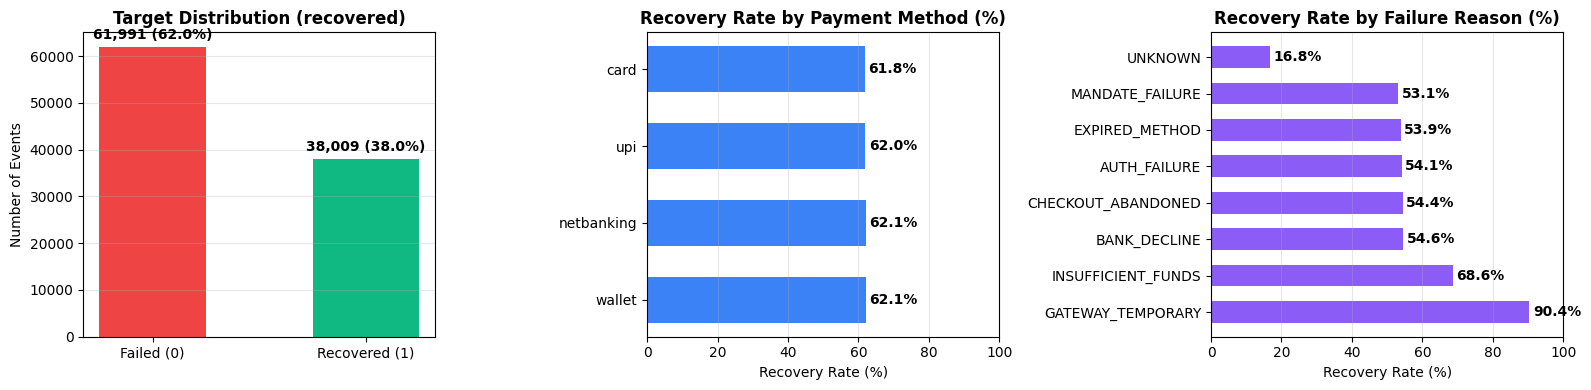

In [3]:
frames = {
    "payment_events": events_raw, "train": train_raw, "validation": validation_raw, "test": test_raw,
    "customer_profiles": profiles_raw, "customer_history_features": history_raw,
}
profile_summary = pd.DataFrame([
    {"dataset": n, "rows": len(d), "columns": d.shape[1], "duplicate_rows": int(d.duplicated().sum()),
     "missing_cells": int(d.isna().sum().sum())}
    for n, d in frames.items() if d is not None
])
display(profile_summary)
profile_summary.to_csv(OUTPUT_DIR / "dataset_profile_summary.csv", index=False)

# Column types and missingness
col_profile = pd.DataFrame({
    "dtype": events_raw.dtypes.astype(str),
    "missing": events_raw.isna().sum(),
    "missing_pct": (events_raw.isna().mean() * 100).round(2),
    "unique": events_raw.nunique(dropna=True),
})
display(col_profile)

# Target variable and key category distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Target distribution
target_counts = events_raw[TARGET].value_counts()
colors = ['#ef4444', '#10b981']
bars = axes[0].bar(["Failed (0)", "Recovered (1)"], target_counts.values, color=colors, width=0.5)
axes[0].set_title(f"Target Distribution ({TARGET})", fontweight="bold")
axes[0].set_ylabel("Number of Events")
axes[0].grid(axis="y", alpha=0.3)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 1000, f"{yval:,} ({yval/len(events_raw)*100:.1f}%)", ha='center', va='bottom', fontweight="semibold")

# 2. Recovery rate by payment method
pm_rec = events_raw.groupby("payment_method")[TARGET].mean().sort_values(ascending=False)
axes[1].barh(pm_rec.index, pm_rec.values * 100, color="#3b82f6", height=0.6)
axes[1].set_title("Recovery Rate by Payment Method (%)", fontweight="bold")
axes[1].set_xlabel("Recovery Rate (%)")
axes[1].set_xlim(0, 100)
axes[1].grid(axis="x", alpha=0.3)
for i, v in enumerate(pm_rec.values * 100):
    axes[1].text(v + 1, i, f"{v:.1f}%", va='center', fontweight="semibold")

# 3. Recovery rate by failure reason
fr_rec = events_raw.groupby("failure_reason")[TARGET].mean().sort_values(ascending=False)
axes[2].barh(fr_rec.index, fr_rec.values * 100, color="#8b5cf6", height=0.6)
axes[2].set_title("Recovery Rate by Failure Reason (%)", fontweight="bold")
axes[2].set_xlabel("Recovery Rate (%)")
axes[2].set_xlim(0, 100)
axes[2].grid(axis="x", alpha=0.3)
for i, v in enumerate(fr_rec.values * 100):
    axes[2].text(v + 1, i, f"{v:.1f}%", va='center', fontweight="semibold")

plt.tight_layout()
plt.show()


## 4. Split and label validation

Checks: binary labels with no missing values; observed counts match the manifest; each split file equals the
rows of `payment_events.csv` tagged with that split (same event IDs and same labels); no event ID occurs twice.

In [4]:
splits_raw = {"train": train_raw, "validation": validation_raw, "test": test_raw}
rows = []
for name, df in splits_raw.items():
    labels = set(df[TARGET].dropna().unique().tolist())
    assert labels <= {0, 1, True, False}, f"{name}: non-binary target {labels}"
    assert not df[TARGET].isna().any(), f"{name}: missing labels"
    tagged = events_raw[events_raw["split"] == name]
    same_ids = set(df["event_id"]) == set(tagged["event_id"])
    merged = df[["event_id", TARGET]].merge(tagged[["event_id", TARGET]], on="event_id", suffixes=("", "_events"))
    rows.append({
        "split": name, "rows": len(df), "manifest_rows": manifest["split_counts"].get(name),
        "positive_rate": round(float(df[TARGET].astype(int).mean()), 4),
        "ids_match_payment_events": same_ids,
        "labels_match_payment_events": bool((merged[TARGET] == merged[f"{TARGET}_events"]).all()),
        "duplicate_event_ids": int(df["event_id"].duplicated().sum()),
    })
split_check = pd.DataFrame(rows)
display(split_check)
assert (split_check["rows"] == split_check["manifest_rows"]).all()
assert split_check["ids_match_payment_events"].all() and split_check["labels_match_payment_events"].all()
assert events_raw["event_id"].is_unique

,split,rows,manifest_rows,positive_rate,ids_match_payment_events,labels_match_payment_events,duplicate_event_ids
0,train,69910,69910,0.6194,True,True,0
1,validation,14924,14924,0.6207,True,True,0
2,test,15166,15166,0.6215,True,True,0


## 5. Is the supplied split chronological?

A model used at decision time predicts **future** events from the past. If the supplied splits cover the same
time range they are a random split, and test metrics measure interpolation rather than forward performance.

,min,max,count
split,,,
train,2026-01-01 00:04:00+00:00,2026-05-19 21:19:00+00:00,69910
validation,2026-01-01 00:18:00+00:00,2026-05-19 21:02:00+00:00,14924
test,2026-01-01 00:22:00+00:00,2026-05-19 21:03:00+00:00,15166


Supplied split is time-overlapping (random): True


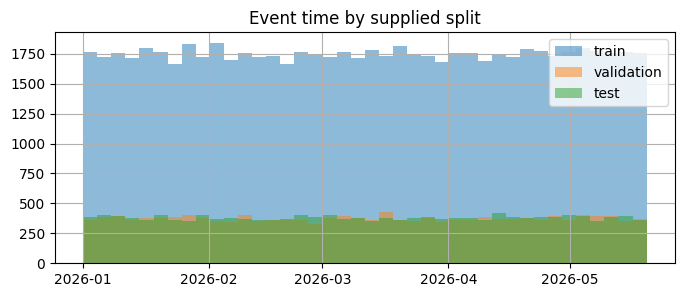

In [5]:
events_raw["occurred_at_ts"] = pd.to_datetime(events_raw["occurred_at"], errors="coerce", utc=True)
assert events_raw["occurred_at_ts"].notna().all(), "unparseable timestamps"
time_ranges = (events_raw.groupby("split")["occurred_at_ts"].agg(["min", "max", "count"])
               .reindex(["train", "validation", "test"]))
display(time_ranges)
overlap = time_ranges.loc["test", "min"] < time_ranges.loc["train", "max"]
print("Supplied split is time-overlapping (random):", bool(overlap))

fig, ax = plt.subplots(figsize=(8, 3))
for name in ["train", "validation", "test"]:
    events_raw.loc[events_raw["split"] == name, "occurred_at_ts"].dt.tz_localize(None).hist(
        ax=ax, bins=40, alpha=0.5, label=name)
ax.set_title("Event time by supplied split"); ax.legend(); plt.show()

## 6. Context tables: join keys

`customer_profiles.csv` and `customer_history_features.csv` can only be used if their `customer_id`s match the
event log. This is measured, not assumed.

In [6]:
event_customers = set(events_raw["customer_id"])
join_audit = []
for name, df in [("customer_profiles", profiles_raw), ("customer_history_features", history_raw)]:
    if df is None:
        continue
    ids = set(df["customer_id"])
    join_audit.append({
        "table": name, "rows": len(df), "unique_ids": len(ids),
        "event_customers_matched": len(event_customers & ids),
        "match_rate_of_event_customers": round(len(event_customers & ids) / len(event_customers), 4),
        "example_id": df["customer_id"].iloc[0],
    })
join_audit = pd.DataFrame(join_audit)
print("example event customer_id:", events_raw["customer_id"].iloc[0])
display(join_audit)

example event customer_id: CUST-00083811


,table,rows,unique_ids,event_customers_matched,match_rate_of_event_customers,example_id
0,customer_profiles,100000,100000,0,0.0,CUST-00001
1,customer_history_features,63154,63154,63154,1.0,CUST-00000001


## 7. Empirical leakage audit

Name-based flags are kept, but each joinable context column is also scored by its **single-feature ROC-AUC
against the event label on the training split**. The history table is a whole-period snapshot (one row per
customer, computed over all events including validation/test), so any column derived from outcomes leaks.
Columns with |AUC − 0.5| > 0.15 that are outcome-derived are excluded.

In [7]:
train_events = events_raw[events_raw["split"] == "train"]
y_tr = train_events[TARGET].astype(int)
leak_rows = []
for name, df in [("customer_profiles", profiles_raw), ("customer_history_features", history_raw)]:
    if df is None:
        continue
    joined = train_events[["customer_id"]].merge(df, on="customer_id", how="left")
    for col in df.columns:
        if col == "customer_id" or not pd.api.types.is_numeric_dtype(df[col]):
            continue
        x = joined[col]
        coverage = float(x.notna().mean())
        auc = roc_auc_score(y_tr[x.notna().to_numpy()], x.dropna()) if coverage > 0 and x.nunique() > 1 else np.nan
        leak_rows.append({"table": name, "column": col, "coverage_on_train_events": round(coverage, 4),
                          "single_feature_auc": None if np.isnan(auc) else round(float(auc), 4)})
leakage_audit = pd.DataFrame(leak_rows)
OUTCOME_DERIVED = {"has_recovered", "previous_recovery_rate", "success_count", "previous_recovery_success_rate",
                   "previous_recovery_count", "payment_success_rate", "successful_transactions"}
leakage_audit["outcome_derived_name"] = leakage_audit["column"].isin(OUTCOME_DERIVED)
leakage_audit["verdict"] = np.select(
    [leakage_audit["coverage_on_train_events"] == 0,
     leakage_audit["outcome_derived_name"] | ((leakage_audit["single_feature_auc"] - 0.5).abs() > 0.15)],
    ["UNJOINABLE (0% key match)", "EXCLUDE: leakage"], default="EXCLUDE: whole-period snapshot, not point-in-time")
display(leakage_audit.sort_values("single_feature_auc", ascending=False, key=lambda s: (s - 0.5).abs()))
leakage_audit.to_csv(OUTPUT_DIR / "leakage_audit.csv", index=False)

,table,column,coverage_on_train_events,single_feature_auc,outcome_derived_name,verdict
20,customer_history_features,previous_recovery_rate,1.0,0.9480,True,EXCLUDE: leakage
14,customer_history_features,success_count,1.0,0.8177,True,EXCLUDE: leakage
22,customer_history_features,has_recovered,1.0,0.7737,True,EXCLUDE: leakage
16,customer_history_features,average_amount_paise,1.0,0.5613,False,"EXCLUDE: whole-period snapshot, not point-in-time"
17,customer_history_features,total_amount_paise,1.0,0.5578,False,"EXCLUDE: whole-period snapshot, not point-in-time"
21,customer_history_features,revenue_at_risk_paise,1.0,0.5578,False,"EXCLUDE: whole-period snapshot, not point-in-time"
19,customer_history_features,checkout_abandonment_rate,1.0,0.4727,False,"EXCLUDE: whole-period snapshot, not point-in-time"
12,customer_history_features,transaction_count,1.0,0.5038,False,"EXCLUDE: whole-period snapshot, not point-in-time"
13,customer_history_features,failure_count,1.0,0.5038,False,"EXCLUDE: whole-period snapshot, not point-in-time"
18,customer_history_features,retry_count_mean,1.0,0.4975,False,"EXCLUDE: whole-period snapshot, not point-in-time"


**Decision.** Neither context table is joined. `customer_profiles` shares no keys with the event log, and every
`customer_history_features` column is a whole-period aggregate (e.g. `previous_recovery_rate` is a direct
function of the labels being predicted). Customer history is instead rebuilt **point-in-time** from the event
log in §9 using only feature columns of earlier events.

## 8. Canonical cleaning

Strip whitespace in strings, cast the label to `int8`, parse timestamps to UTC, and derive hour / day-of-week
(cyclical calendar features that are stationary). Month and day-of-month are **not** used as features because
a forward-in-time test period would contain values unseen in training. Duplicates are reported, not dropped
(there are none).

In [8]:
events = events_raw.rename(columns={"split": "supplied_split"}).copy()
for col in events.select_dtypes(include=["object", "string"]).columns:
    events[col] = events[col].astype("string").str.strip()
events[TARGET] = events[TARGET].astype("int8")
events["occurred_at"] = events.pop("occurred_at_ts")
events["event_hour_utc"] = events["occurred_at"].dt.hour.astype("int8")
events["event_dayofweek_utc"] = events["occurred_at"].dt.dayofweek.astype("int8")
print("duplicate rows:", int(events.duplicated().sum()))
print("constant columns:", [c for c in events.columns if events[c].nunique(dropna=False) == 1])

duplicate rows: 0
constant columns: ['schema_version', 'currency', 'is_synthetic']


## 9. Point-in-time customer history features

Events are ordered per customer by `(occurred_at, event_id)`. For each event the features below use only
**earlier** events of the same customer, across all splits, and only their *input* fields — never `recovered`.
This mirrors what the backend can know at prediction time.

,count,mean,std,min,25%,50%,75%,max
cust_prior_events,100000.0,0.502250,0.768571,0.0,0.000000,0.000000,1.000000,7.000000e+00
cust_prior_amount_mean,36846.0,701234.621994,896739.261115,20105.0,180551.500000,357474.500000,844142.000000,4.997890e+06
cust_prior_retry_total,100000.0,0.750480,1.397018,0.0,0.000000,0.000000,1.000000,1.600000e+01
cust_prior_checkout_abandoned,100000.0,0.098840,0.319487,0.0,0.000000,0.000000,0.000000,4.000000e+00
cust_prior_failed_payment,100000.0,0.275110,0.548259,0.0,0.000000,0.000000,0.000000,6.000000e+00
cust_prior_failed_subscription,100000.0,0.128300,0.368375,0.0,0.000000,0.000000,0.000000,5.000000e+00
cust_prior_same_failure_reason,100000.0,0.088740,0.304313,0.0,0.000000,0.000000,0.000000,3.000000e+00
hours_since_prev_event,36846.0,944.565055,734.396590,0.0,338.533333,776.566667,1408.945833,3.309883e+03


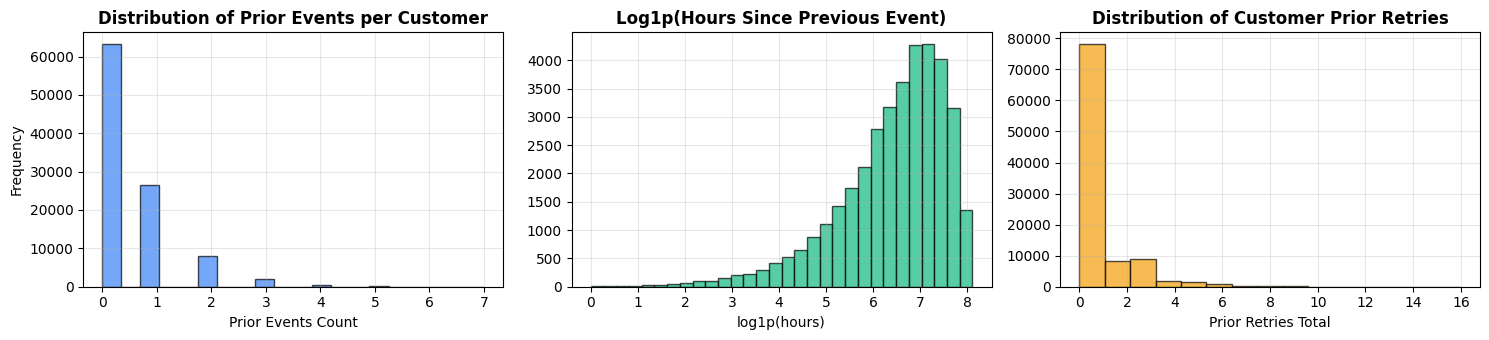

In [9]:
events = events.sort_values(["customer_id", "occurred_at", "event_id"]).reset_index(drop=True)
g = events.groupby("customer_id", sort=False)

events["cust_prior_events"] = g.cumcount().astype("int16")
prev_ts = g["occurred_at"].shift(1)
events["hours_since_prev_event"] = (events["occurred_at"] - prev_ts).dt.total_seconds() / 3600.0
prior_amount_sum = g["amount_paise"].cumsum() - events["amount_paise"]
events["cust_prior_amount_mean"] = (prior_amount_sum / events["cust_prior_events"].replace(0, np.nan))
events["cust_prior_retry_total"] = (g["retry_count"].cumsum() - events["retry_count"]).astype("int16")
for et in sorted(events["event_type"].unique()):
    flag = (events["event_type"] == et).astype("int16")
    events[f"cust_prior_{et.lower()}"] = (flag.groupby(events["customer_id"]).cumsum() - flag).astype("int16")
events["cust_prior_same_failure_reason"] = (
    events.groupby(["customer_id", "failure_reason"], sort=False).cumcount().astype("int16"))

# Sanity: the first event of every customer has no history.
first = events["cust_prior_events"] == 0
assert events.loc[first, "hours_since_prev_event"].isna().all()
assert (events.loc[first, "cust_prior_retry_total"] == 0).all()
assert (events["hours_since_prev_event"].dropna() >= 0).all()
HISTORY_FEATURES = [c for c in events.columns if c.startswith("cust_prior_")] + ["hours_since_prev_event"]
display(events[HISTORY_FEATURES].describe().T)

# Distribution of engineered point-in-time features
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(events["cust_prior_events"], bins=20, color="#3b82f6", edgecolor="black", alpha=0.7)
axes[0].set_title("Distribution of Prior Events per Customer", fontweight="bold")
axes[0].set_xlabel("Prior Events Count")
axes[0].set_ylabel("Frequency")
axes[0].grid(alpha=0.3)

hours_clean = events["hours_since_prev_event"].dropna()
axes[1].hist(np.log1p(hours_clean), bins=30, color="#10b981", edgecolor="black", alpha=0.7)
axes[1].set_title("Log1p(Hours Since Previous Event)", fontweight="bold")
axes[1].set_xlabel("log1p(hours)")
axes[1].grid(alpha=0.3)

axes[2].hist(events["cust_prior_retry_total"], bins=15, color="#f59e0b", edgecolor="black", alpha=0.7)
axes[2].set_title("Distribution of Customer Prior Retries", fontweight="bold")
axes[2].set_xlabel("Prior Retries Total")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 10. Chronological split

`chrono_split` assigns the earliest 70% of events to train, the next 15% to validation and the latest 15% to
test, using timestamp cut-offs so that no test event precedes any training event. The supplied split is kept
as `supplied_split` for comparison. Customers may appear in several periods — that is realistic (returning
customers), and history features never look forward.

,rows,positive_rate,start,end
chrono_split,,,,
train,70000,0.619043,2026-01-01 00:04:00+00:00,2026-04-08 10:57:00+00:00
validation,15000,0.623200,2026-04-08 10:59:00+00:00,2026-04-29 06:16:00+00:00
test,15000,0.620667,2026-04-29 06:18:00+00:00,2026-05-19 21:19:00+00:00


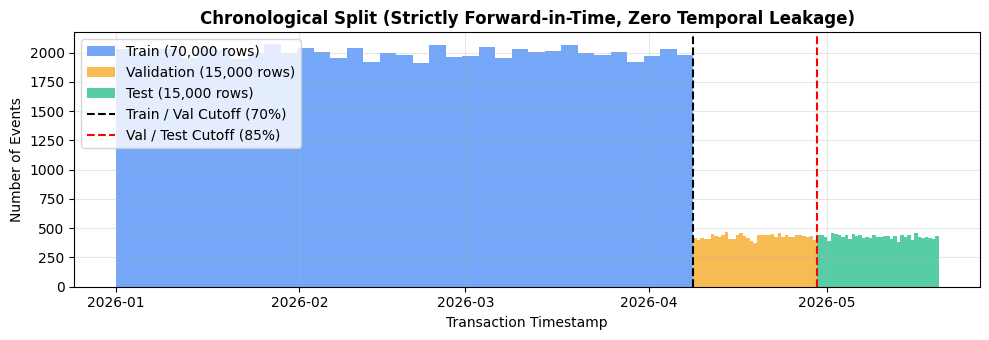

In [10]:
t70, t85 = events["occurred_at"].quantile([0.70, 0.85])
events["chrono_split"] = np.select(
    [events["occurred_at"] < t70, events["occurred_at"] < t85], ["train", "validation"], default="test")
chrono_summary = events.groupby("chrono_split").agg(
    rows=(TARGET, "size"), positive_rate=(TARGET, "mean"),
    start=("occurred_at", "min"), end=("occurred_at", "max")).reindex(["train", "validation", "test"])
display(chrono_summary)
assert chrono_summary.loc["train", "end"] < chrono_summary.loc["validation", "start"]
assert chrono_summary.loc["validation", "end"] < chrono_summary.loc["test", "start"]

# Chronological forward-in-time timeline plot
fig, ax = plt.subplots(figsize=(10, 3.5))
split_colors = {"train": "#3b82f6", "validation": "#f59e0b", "test": "#10b981"}
for s in ["train", "validation", "test"]:
    sub = events[events["chrono_split"] == s]["occurred_at"].dt.tz_localize(None)
    ax.hist(sub, bins=35, color=split_colors[s], alpha=0.7, label=f"{s.capitalize()} ({len(sub):,} rows)")
ax.axvline(t70.tz_localize(None), color="black", linestyle="--", lw=1.5, label="Train / Val Cutoff (70%)")
ax.axvline(t85.tz_localize(None), color="red", linestyle="--", lw=1.5, label="Val / Test Cutoff (85%)")
ax.set_title("Chronological Split (Strictly Forward-in-Time, Zero Temporal Leakage)", fontweight="bold")
ax.set_xlabel("Transaction Timestamp")
ax.set_ylabel("Number of Events")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 11. Feature specification

In [11]:
CATEGORICAL = ["event_type", "failure_reason", "payment_method", "device_type", "country"]
NUMERIC = ["amount_paise", "retry_count", "event_hour_utc", "event_dayofweek_utc", *HISTORY_FEATURES]
EXCLUDED = {
    TARGET: "target", "event_id": "identifier", "customer_id": "identifier (used only for grouping)",
    "occurred_at": "raw timestamp (ordering only)", "supplied_split": "split metadata",
    "chrono_split": "split metadata", "schema_version": "constant metadata", "currency": "constant (INR)",
    "is_synthetic": "constant metadata",
}
assert set(CATEGORICAL + NUMERIC + list(EXCLUDED)) == set(events.columns), (
    set(events.columns) ^ set(CATEGORICAL + NUMERIC + list(EXCLUDED)))
feature_spec = {
    "feature_version": "rr-features.v2",
    "target": TARGET,
    "categorical": CATEGORICAL,
    "numeric": NUMERIC,
    "history_features": HISTORY_FEATURES,
    "excluded": EXCLUDED,
    "sequence_order": ["customer_id", "occurred_at", "event_id"],
    "split_columns": {"chrono_split": "primary (forward-in-time)", "supplied_split": "random, for comparison"},
}
print(json.dumps(feature_spec, indent=2))

{
  "feature_version": "rr-features.v2",
  "target": "recovered",
  "categorical": [
    "event_type",
    "failure_reason",
    "payment_method",
    "device_type",
    "country"
  ],
  "numeric": [
    "amount_paise",
    "retry_count",
    "event_hour_utc",
    "event_dayofweek_utc",
    "cust_prior_events",
    "cust_prior_amount_mean",
    "cust_prior_retry_total",
    "cust_prior_checkout_abandoned",
    "cust_prior_failed_payment",
    "cust_prior_failed_subscription",
    "cust_prior_same_failure_reason",
    "hours_since_prev_event"
  ],
  "history_features": [
    "cust_prior_events",
    "cust_prior_amount_mean",
    "cust_prior_retry_total",
    "cust_prior_checkout_abandoned",
    "cust_prior_failed_payment",
    "cust_prior_failed_subscription",
    "cust_prior_same_failure_reason",
    "hours_since_prev_event"
  ],
  "excluded": {
    "recovered": "target",
    "event_id": "identifier",
    "customer_id": "identifier (used only for grouping)",
    "occurred_at": "raw tim

## 12. Export

In [12]:
def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


out_events = OUTPUT_DIR / "events_clean.parquet"
events.to_parquet(out_events, index=False, compression="snappy")
(OUTPUT_DIR / "feature_spec.json").write_text(json.dumps(feature_spec, indent=2), encoding="utf-8")

preprocessing_manifest = {
    "dataset_version": manifest.get("dataset_version"),
    "all_data_synthetic": manifest.get("all_data_is_synthetic"),
    "rows": len(events),
    "feature_version": feature_spec["feature_version"],
    "supplied_split_counts": events["supplied_split"].value_counts().to_dict(),
    "chrono_split_counts": events["chrono_split"].value_counts().to_dict(),
    "chrono_cutoffs_utc": {"validation_start": str(t70), "test_start": str(t85)},
    "supplied_split_is_time_overlapping": bool(overlap),
    "context_tables_joined": False,
    "context_table_join_audit": join_audit.to_dict(orient="records"),
    "missing_value_policy": "NaN kept (first event has no history); models impute/handle internally",
    "processing_engine": "pandas (local, single node) - not Spark/HDFS",
    "seed": SEED,
}
(OUTPUT_DIR / "preprocessing_manifest.json").write_text(
    json.dumps(preprocessing_manifest, indent=2, default=str), encoding="utf-8")

checksums = pd.DataFrame([
    {"file": p.name, "bytes": p.stat().st_size, "sha256": sha256_file(p)}
    for p in sorted(OUTPUT_DIR.iterdir()) if p.is_file() and p.name != "output_checksums.csv"
])
checksums.to_csv(OUTPUT_DIR / "output_checksums.csv", index=False)
display(checksums)

,file,bytes,sha256
0,dataset_profile_summary.csv,218,ead20f60c8f9b952f78a1a28fd19ae553da8f722f723dc...
1,events_clean.parquet,3561902,1a7f65f1735670ae3b0a1ebdaae2e12de591bf5287ecc1...
2,feature_spec.json,1481,4cbe6d145253f0356363e503de159ed3b32a3d4d98b94c...
3,leakage_audit.csv,2153,07793ab3ba9f0c04904df0a97ad961acac9d3f0ff7a51d...
4,preprocessing_manifest.json,1243,6c15c9d464e01175a9d17aa96bb32766f63d04c3c31054...


## 13. Final checks

In [13]:
reloaded = pd.read_parquet(out_events)
checks = {
    "rows_preserved": len(reloaded) == len(events_raw),
    "event_ids_unique": bool(reloaded["event_id"].is_unique),
    "target_binary": set(reloaded[TARGET].unique()) <= {0, 1},
    "no_target_in_features": TARGET not in CATEGORICAL + NUMERIC,
    "chrono_split_forward_in_time": bool(
        reloaded.loc[reloaded.chrono_split == "train", "occurred_at"].max()
        < reloaded.loc[reloaded.chrono_split == "test", "occurred_at"].min()),
    "context_tables_not_joined": True,
    "all_data_synthetic": bool(manifest.get("all_data_is_synthetic")),
}
print(json.dumps(checks, indent=2))
assert all(checks.values()), checks
print("Preprocessing complete ->", OUTPUT_DIR)

{
  "rows_preserved": true,
  "event_ids_unique": true,
  "target_binary": true,
  "no_target_in_features": true,
  "chrono_split_forward_in_time": true,
  "context_tables_not_joined": true,
  "all_data_synthetic": true
}
Preprocessing complete -> C:\Users\moury\Coding\Projects\Big-Data\RevenueRescue AI\data\preprocessed
